# Multi-Armed Bandit (Reinforcement Learning)

Epsilon-greedy agent that learns which of 5 ads gets the most clicks. Libraries: `numpy`, `matplotlib`.

Full explanation: see [Multi_Armed_Bandit_Guide.md](Multi_Armed_Bandit_Guide.md).

## 1. Setup

In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3})

SEED = 42
os.makedirs("images", exist_ok=True)   # plots are saved here for the README

## 2. Environment: 5 ads with hidden click rates

In [2]:
class BernoulliBandit:
    """A row of ads. Each ad has a hidden click-through rate."""

    def __init__(self, true_ctr, rng):
        self.true_ctr = np.array(true_ctr)
        self.n_arms = len(true_ctr)
        self.best_arm = int(np.argmax(self.true_ctr))
        self.rng = rng

    def pull(self, arm):
        """Show ad number `arm`. Returns 1 (click) or 0 (no click)."""
        return float(self.rng.random() < self.true_ctr[arm])


TRUE_CTR = [0.05, 0.10, 0.20, 0.08, 0.15]   # hidden from the agent
ad_names = [f"Ad {i}" for i in range(len(TRUE_CTR))]

print("Best ad:", ad_names[int(np.argmax(TRUE_CTR))], "with CTR", max(TRUE_CTR))

Best ad: Ad 2 with CTR 0.2


## 3. Agent: epsilon-greedy

In [3]:
class EpsilonGreedyAgent:
    def __init__(self, n_arms, epsilon, rng):
        self.n_arms = n_arms
        self.epsilon = epsilon          # a number, or a function of the step t
        self.rng = rng
        self.Q = np.zeros(n_arms)       # estimated click rate of each ad
        self.N = np.zeros(n_arms)       # how many times each ad was shown

    def current_epsilon(self, t):
        return self.epsilon(t) if callable(self.epsilon) else self.epsilon

    def select_action(self, t):
        if self.rng.random() < self.current_epsilon(t):
            return int(self.rng.integers(self.n_arms))          # explore
        best = np.flatnonzero(self.Q == self.Q.max())            # exploit
        return int(self.rng.choice(best))                        # break ties randomly

    def update(self, arm, reward):
        self.N[arm] += 1
        self.Q[arm] += (reward - self.Q[arm]) / self.N[arm]

## 4. Single run

In [4]:
rng = np.random.default_rng(SEED)
env = BernoulliBandit(TRUE_CTR, rng)
agent = EpsilonGreedyAgent(env.n_arms, epsilon=0.1, rng=rng)

STEPS = 1000
total_reward = 0
for t in range(STEPS):
    arm = agent.select_action(t)
    reward = env.pull(arm)
    agent.update(arm, reward)
    total_reward += reward

print(f"Total clicks: {int(total_reward)} out of {STEPS} visitors  (CTR {total_reward / STEPS:.3f})")
print(f"Best possible CTR if we always showed the best ad: {max(TRUE_CTR):.3f}")
print()
for name, true, est, n in zip(ad_names, TRUE_CTR, agent.Q, agent.N):
    print(f"{name}: true CTR {true:.2f} | estimated {est:.3f} | shown {int(n)} times")

Total clicks: 190 out of 1000 visitors  (CTR 0.190)
Best possible CTR if we always showed the best ad: 0.200

Ad 0: true CTR 0.05 | estimated 0.063 | shown 16 times
Ad 1: true CTR 0.10 | estimated 0.000 | shown 21 times
Ad 2: true CTR 0.20 | estimated 0.199 | shown 919 times
Ad 3: true CTR 0.08 | estimated 0.130 | shown 23 times
Ad 4: true CTR 0.15 | estimated 0.143 | shown 21 times


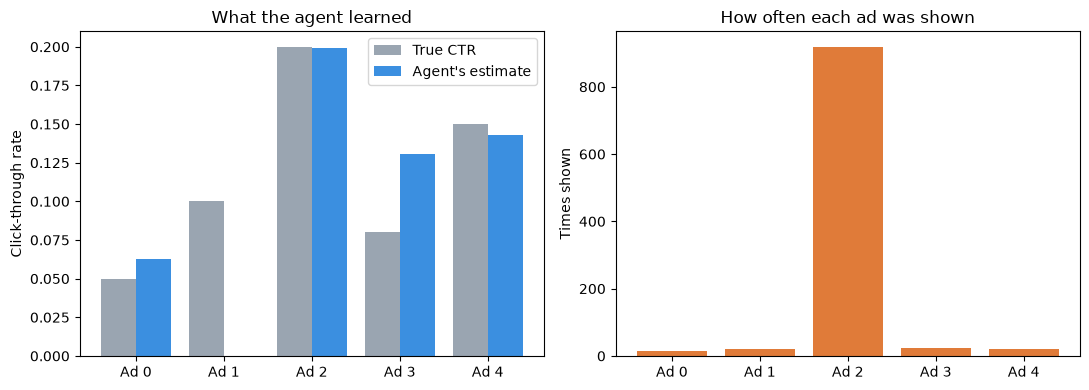

In [5]:
x = np.arange(len(TRUE_CTR))
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].bar(x - 0.2, TRUE_CTR, width=0.4, label="True CTR", color="#9aa5b1")
axes[0].bar(x + 0.2, agent.Q, width=0.4, label="Agent's estimate", color="#3b8fe0")
axes[0].set_xticks(x); axes[0].set_xticklabels(ad_names)
axes[0].set_ylabel("Click-through rate"); axes[0].set_title("What the agent learned"); axes[0].legend()

axes[1].bar(x, agent.N, color="#e07b39")
axes[1].set_xticks(x); axes[1].set_xticklabels(ad_names)
axes[1].set_ylabel("Times shown"); axes[1].set_title("How often each ad was shown")

for ax in axes: ax.grid(False)
plt.tight_layout()
plt.savefig("images/single_run.png", dpi=150, bbox_inches="tight")
plt.show()

## 5. Compare strategies

In [6]:
RUNS = 300
STEPS = 1500

def run_experiment(make_agent, runs=RUNS, steps=STEPS, seed=SEED):
    """Run the same strategy many times and average the results over runs."""
    rewards = np.zeros((runs, steps))
    optimal = np.zeros((runs, steps))
    regret = np.zeros((runs, steps))
    seeds = np.random.SeedSequence(seed).spawn(runs)

    for r in range(runs):
        rng = np.random.default_rng(seeds[r])
        env = BernoulliBandit(TRUE_CTR, rng)
        agent = make_agent(env.n_arms, rng)
        for t in range(steps):
            arm = agent.select_action(t)
            reward = env.pull(arm)
            agent.update(arm, reward)
            rewards[r, t] = reward
            optimal[r, t] = (arm == env.best_arm)
            regret[r, t] = env.true_ctr[env.best_arm] - env.true_ctr[arm]
    return rewards.mean(axis=0), optimal.mean(axis=0) * 100, regret.mean(axis=0)


strategies = {
    "Random (eps=1.0)":   lambda n, rng: EpsilonGreedyAgent(n, 1.0, rng),
    "Greedy (eps=0)":     lambda n, rng: EpsilonGreedyAgent(n, 0.0, rng),
    "Epsilon 0.01":       lambda n, rng: EpsilonGreedyAgent(n, 0.01, rng),
    "Epsilon 0.1":        lambda n, rng: EpsilonGreedyAgent(n, 0.1, rng),
    "Epsilon 0.3":        lambda n, rng: EpsilonGreedyAgent(n, 0.3, rng),
}

results = {name: run_experiment(make) for name, make in strategies.items()}
print("Done:", list(results))

Done: ['Random (eps=1.0)', 'Greedy (eps=0)', 'Epsilon 0.01', 'Epsilon 0.1', 'Epsilon 0.3']


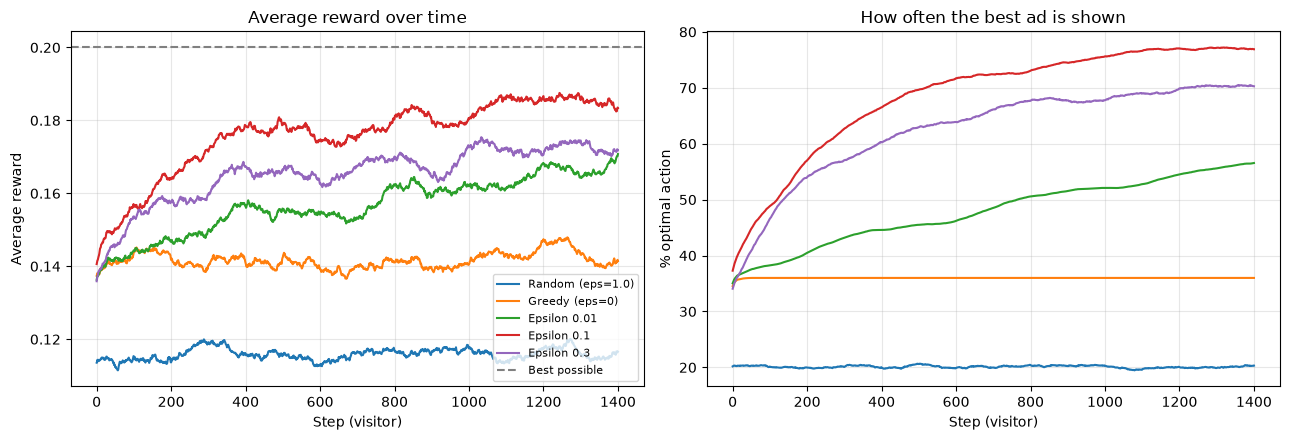

In [8]:
def smooth(y, window=100):
    return np.convolve(y, np.ones(window) / window, mode="valid")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for name, (avg_reward, pct_optimal, _) in results.items():
    axes[0].plot(smooth(avg_reward), label=name)
    axes[1].plot(smooth(pct_optimal), label=name)

axes[0].axhline(max(TRUE_CTR), color="gray", linestyle="--", label="Best possible")
axes[0].set_xlabel("Step (visitor)"); axes[0].set_ylabel("Average reward"); axes[0].set_title("Average reward over time")
axes[1].set_xlabel("Step (visitor)"); axes[1].set_ylabel("% optimal action"); axes[1].set_title("How often the best ad is shown")
axes[0].legend(loc="lower right", fontsize=8)
plt.tight_layout()
plt.savefig("images/strategy_comparison.png", dpi=150, bbox_inches="tight")
plt.show()

## 6. Decaying epsilon

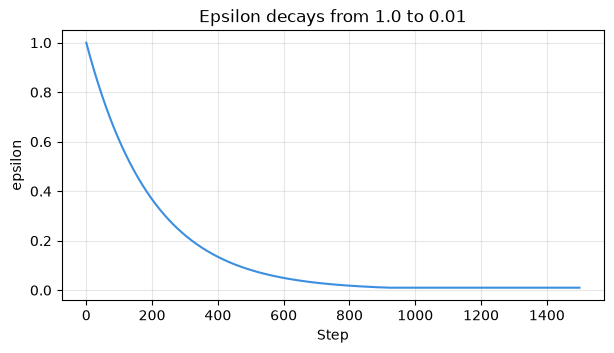

In [9]:
def decaying_epsilon(t):
    return max(0.01, 0.995 ** t)

results["Decaying epsilon"] = run_experiment(
    lambda n, rng: EpsilonGreedyAgent(n, decaying_epsilon, rng))

steps_axis = np.arange(STEPS)
plt.figure(figsize=(7, 3.5))
plt.plot(steps_axis, [decaying_epsilon(t) for t in steps_axis], color="#3b8fe0")
plt.xlabel("Step"); plt.ylabel("epsilon"); plt.title("Epsilon decays from 1.0 to 0.01")
plt.savefig("images/epsilon_decay.png", dpi=150, bbox_inches="tight")
plt.show()

## 7. Cumulative regret

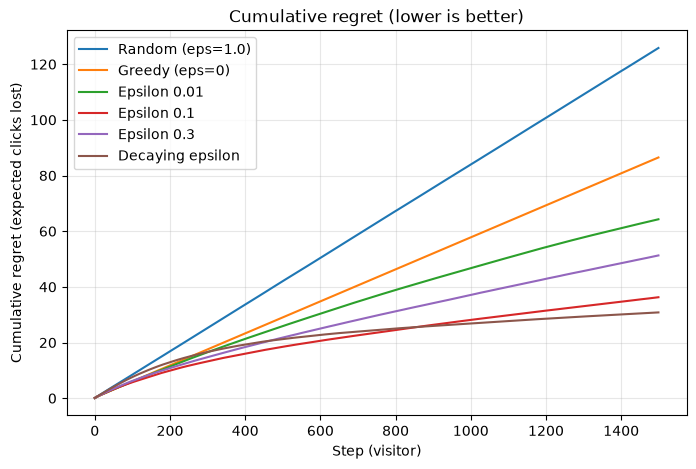

In [11]:
plt.figure(figsize=(8, 5))
for name, (_, _, regret) in results.items():
    plt.plot(np.cumsum(regret), label=name)
plt.xlabel("Step (visitor)"); plt.ylabel("Cumulative regret (expected clicks lost)")
plt.title("Cumulative regret (lower is better)")
plt.legend()
plt.savefig("images/cumulative_regret.png", dpi=150, bbox_inches="tight")
plt.show()

## 8. Final comparison

In [12]:
import pandas as pd

rows = []
for name, (avg_reward, pct_optimal, regret) in results.items():
    rows.append({
        "Strategy": name,
        "Avg reward (last 500 steps)": avg_reward[-500:].mean(),
        "% optimal ad (last 500 steps)": pct_optimal[-500:].mean(),
        "Total regret": regret.sum(),
    })

summary = pd.DataFrame(rows).set_index("Strategy").round(3)
summary.sort_values("Total regret")

,Avg reward (last 500 steps),% optimal ad (last 500 steps),Total regret
Strategy,,,
Decaying epsilon,0.193,86.310,30.828
Epsilon 0.1,0.184,76.663,36.283
Epsilon 0.3,0.172,69.451,51.296
Epsilon 0.01,0.165,54.305,64.289
Greedy (eps=0),0.143,36.000,86.492
Random (eps=1.0),0.116,20.034,125.819


Results and conclusions are explained in [Multi_Armed_Bandit_Guide.md](Multi_Armed_Bandit_Guide.md).